In [2]:
import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import kagglehub
from sklearn.model_selection import StratifiedGroupKFold

BASE = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
df = pd.read_csv(f"{BASE}/HAM10000_metadata.csv")

paths = {}
for part in ["HAM10000_images_part_1", "HAM10000_images_part_2"]:
    d = f"{BASE}/{part}"
    for f in os.listdir(d):
        paths[f.replace(".jpg", "")] = f"{d}/{f}"
df["path"] = df["image_id"].map(paths)

def split(data, n_splits, seed=42):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rest, part = next(sgkf.split(data, data["dx"], groups=data["lesion_id"]))
    return data.iloc[rest], data.iloc[part]

train_val, test = split(df, 10)
train, val = split(train_val, 9)
print(len(train), len(val), len(test))

CLASSES = sorted(df["dx"].unique())
label_to_idx = {c: i for i, c in enumerate(CLASSES)}
IMG_SIZE = 128
BATCH = 32

def make_ds(data):
    x = data["path"].values
    y = data["dx"].map(label_to_idx).values
    ds = tf.data.Dataset.from_tensor_slices((x, y))

    def load(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
        return img, label

    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

test_ds = make_ds(test)
print(CLASSES)

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
8013 1010 992
['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


In [3]:
from google.colab import files
from tensorflow import keras

uploaded = files.upload()
model = keras.models.load_model("mobilenetv2_ft.keras")
print(model.name)

Saving mobilenetv2_ft.keras to mobilenetv2_ft.keras
mobilenetv2_ft


31/31 ━━━━━━━━━━━━━━━━━━━━ 7s 119ms/step
              precision    recall  f1-score   support

       akiec      0.556     0.132     0.213        38
         bcc      0.611     0.667     0.638        66
         bkl      0.532     0.584     0.557       101
          df      0.350     0.700     0.467        10
         mel      0.477     0.477     0.477       111
          nv      0.908     0.906     0.907       651
        vasc      0.632     0.800     0.706        15

    accuracy                          0.776       992
   macro avg      0.581     0.609     0.566       992
weighted avg      0.778     0.776     0.771       992

ROC-AUC macro (OvR): 0.937


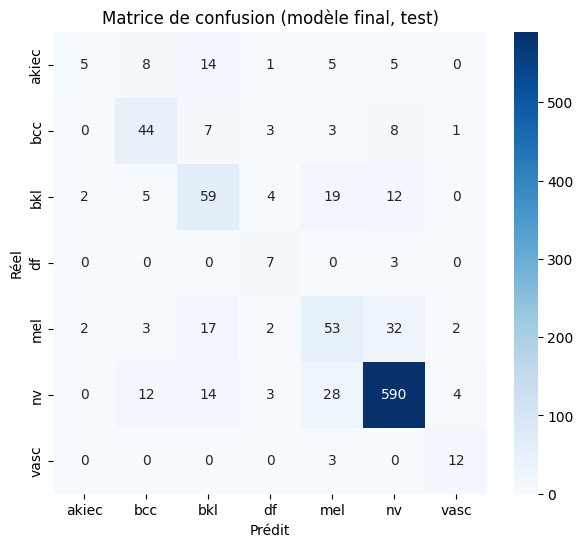

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

y_true = np.concatenate([y.numpy() for _, y in test_ds])
probs = model.predict(test_ds)
y_pred = np.argmax(probs, axis=1)

report = classification_report(y_true, y_pred, target_names=CLASSES, digits=3, zero_division=0)
print(report)
print("ROC-AUC macro (OvR):", round(roc_auc_score(y_true, probs, multi_class="ovr", average="macro"), 3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion (modèle final, test)")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

with open("classification_report.txt", "w") as f:
    f.write(report)
with open("class_names.json", "w") as f:
    json.dump(CLASSES, f)

files.download("confusion_matrix.png")
files.download("classification_report.txt")
files.download("class_names.json")